<a id="0"></a>
 # Table of Contents  

1. [Project Overview](#1)
    1. [Business Context](#2)
    2. [Objective](#3)
    3. [Business Questions](#4)
    4. [Known Data Limitations](#5)
2. [EDA](#6)
    1. [Data Preparation](#7)
        1. [Importing libraries and data](#8)
        2. [Google Analytics](#9)
        3. [Order Data](#10)
        4. [Sales Data](#11)
        5. [Visit Plan Data](#12)
        6. [Customer Data](#13)
        7. [Cutoff Time Data](#14)
        8. [Operation Data](#15)
        9. [Material Data](#16)
        10. [Other Data Preparation Steps](#17)  
    2. [Abandon Analysis](#18)
        1. [Device & Channel](#19)
        2. [Behavioral Patterns](#20)
        3. [Customer & Frequency](#21)
        4. [Temporal Patterns](#22)       

<a id="1"></a>
# 1. Project Overview

Created By: Xinyuan Chen, Linh Do, Mike Hanger

<a id="2"></a> 
## A.Business Context 
MyCoke360 is Swire Coca-Cola’s digital ordering platform for B2B customers such as restaurants, schools, and hospitals. Many customers add products to their online carts but fail to complete purchases before their next scheduled order date. This cart abandonment behavior causes inefficiencies in production scheduling, order fulfillment, and revenue forecasting.
<a id="3"></a> 
## B. Project Objective
Identify behavioral patterns behind cart abandonment and recovery behavior on MyCoke360. Discover insights and actionable recommendations to increase order completion rate and reduce revenue loss.（**Note:** Cart abandonment is when a customer adds an item and does not make a purchase by the next order date.）
<a id="4"></a>
## C. Business Questions

**Question 1:** What (sequence of) behaviors are the strongest predictors of cart abandonment?  
**KPI:** Frequency and type of events before abandonment across sessions.  

**Question 2:** What behaviors lead to a customer returning to the cart after abandonment?  
**Recovery:** Completed checkout after initial cart abandonment within X days.  
**KPI:** Recovery rate by user behavior / device.  

**Question 3:** What does the customer do after cart abandonment? Either go to another platform or churn?  
**KPI:** Abandonment-to-alternative-method conversion rate.  

**Question 4:** What is the financial impact of cart abandonment on total MyCoke360 revenue and product mix?  
In other words, what is the estimated revenue lost from abandoned carts?  
**KPI:** \$ value of products in abandoned carts vs. total revenue, by brand/pack type.  

**Question 5:** What are common products (SKU) in cart abandonment?  
**KPI:** Abandoned cart count and rate per material, by pack size/type, brand, flavor, etc.  

**Question 6:** How does cart abandonment vary by device type and how can it be reduced?  
(Desktop vs. Mobile vs. App)  
**KPI:** Desktop vs. Mobile vs. App abandonment patterns. 

<a id="5"></a> 
## D. Known Data Limitations

**Mismatch between GA and MyCoke360:**  

GA does not capture all events. This is known because some order windows in the GA data do not have a purchase event. However, there is sometimes a purchase on MyCoke360 in that order window in the Orders table.  

Using the Orders table, missing purchase events are accounted for when determining abandoned carts. 

- **Order table:**  
    Mismatch between “add to cart” items in GA, GA purchase items, and items in the Orders table.  

- **Mobile purchases:**  
    Items purchased are blank.  

- **Tracked cart contents:**  
    May not match the final purchased items (incomplete event data).  

- **Purchase events in GA:**  
    May not align with order records in the Orders table.  

- **Matching by date and account ID:**  
    Is unreliable, since customers sometimes place multiple orders through different channels on the same day.

<a id="6"></a>
# 2.EDA

This section focuses on data preparation. The main steps are summarized below.

* **Datasets used:** Google Analytics (GA), Orders, Visit Plan, Customer, Material, and Sales.
* **Timestamp handling:** converted all date/time columns to UTC for consistency.
* **Duplicates removed:** based on `customer_id` + event/order timestamp.
* **Missing values:** filled or dropped depending on availability (especially `frequency_days` and `anchor_date`).
* **Data types:** converted numeric and categorical columns to correct formats.
* **Feature engineering:**

  * Calculated next expected order date using `anchor_date` and `frequency_days`.
  * Defined **order windows** between GA events and next expected order.
  * Created **is_abandoned = 1** if no `add_to_cart` and no `purchase` in that window.
* **Final datasets:**

  * `windows` → order windows with abandon flag
  * `cust_abandon` → abandon rate per customer
  * `due_series` → abandon rate over time

    

<a id="7"></a>
## A. Data Preparation
<a id="8"></a>
### a. Importing libraries and data

In [514]:
# Data Handling 
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns           
import plotly.express as px     

# Dates
from datetime import datetime, date, time, timedelta
from zoneinfo import ZoneInfo

# Stats & ML
from scipy import stats
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# Utilities
import os
import glob
import json          
import warnings
from pathlib import Path
from collections import Counter
from itertools import chain
from pandas.api.types import CategoricalDtype  
from IPython.display import display, HTML

In [515]:
# Import data
ga = pd.read_csv("google_analytics.csv")
customer = pd.read_csv("customer.csv")
cutoff_times = pd.read_csv("cutoff_times.csv")
orders = pd.read_csv("orders.csv")
sales = pd.read_csv("sales.csv")
visit_plan = pd.read_csv("visit_plan.csv", low_memory = False)
material = pd.read_csv("material.csv")
operating_hours = pd.read_csv("operating_hours.csv")

In [516]:
orders

,CUSTOMER_ID,CREATED_DATE_EST,CREATED_DATE_UTC,MATERIAL_ID,ORDER_QUANTITY,ORDER_TYPE,PLANT_ID
0,600265510,2025-01-10,2025-01-10T22:40:25.000Z,152965.0,1.0,CALL CENTER,G267
1,600584506,2024-11-22,2024-11-22T17:34:30.000Z,156127.0,1.0,SALES REP,G221
2,600686120,2024-06-04,2024-06-05T00:29:33.000Z,103886.0,1.0,SALES REP,G291
3,501087671,2024-12-03,2024-12-03T18:14:23.000Z,134926.0,2.0,SALES REP,G163
4,501680332,2025-03-31,2025-03-31T22:33:07.000Z,152196.0,1.0,SALES REP,G221
...,...,...,...,...,...,...,...
1662152,501080847,2024-11-20,2024-11-20T18:23:04.000Z,119827.0,1.0,SALES REP,G142
1662153,501390067,2024-09-30,2024-09-30T21:20:56.000Z,412591.0,6.0,MYCOKE360,G238
1662154,600584687,2024-10-08,2024-10-08T21:48:02.000Z,116153.0,2.0,SALES REP,G221
1662155,501461409,2024-09-06,2024-09-06T15:39:02.000Z,156184.0,1.0,SALES REP,G261


In [517]:
unique_count = orders['CUSTOMER_ID'].nunique()


unique_count

6166

<a id="9"></a>
### b. Google Analytics

In [519]:
ga.info()
ga.describe(include='all')
ga.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3704088 entries, 0 to 3704087
Data columns (total 10 columns):
 #   Column                    Dtype 
---  ------                    ----- 
 0   CUSTOMER_ID               int64 
 1   EVENT_DATE                object
 2   EVENT_TIMESTAMP           object
 3   EVENT_NAME                object
 4   DEVICE_CATEGORY           object
 5   DEVICE_MOBILE_BRAND_NAME  object
 6   DEVICE_OPERATING_SYSTEM   object
 7   EVENT_PAGE_NAME           object
 8   EVENT_PAGE_TITLE          object
 9   ITEMS                     object
dtypes: int64(1), object(9)
memory usage: 282.6+ MB


CUSTOMER_ID                       0
EVENT_DATE                        0
EVENT_TIMESTAMP                   0
EVENT_NAME                        0
DEVICE_CATEGORY                   0
DEVICE_MOBILE_BRAND_NAME      39468
DEVICE_OPERATING_SYSTEM           0
EVENT_PAGE_NAME             1002510
EVENT_PAGE_TITLE             318091
ITEMS                             0
dtype: int64

In [520]:
# Convert data dates & timestamps
ga['EVENT_DATE'] = pd.to_datetime(ga['EVENT_DATE'])
ga['EVENT_TIMESTAMP'] = pd.to_datetime(ga['EVENT_TIMESTAMP'])

# Ensure categorical columns are set properly
categorical_cols = ['EVENT_NAME','DEVICE_CATEGORY',
                    'DEVICE_MOBILE_BRAND_NAME','DEVICE_OPERATING_SYSTEM',
                    'EVENT_PAGE_NAME','EVENT_PAGE_TITLE']
for col in categorical_cols:
    ga[col] = ga[col].astype('category')

# remove duplication
ga = ga.drop_duplicates()

# Handle Missing Value
ga['DEVICE_MOBILE_BRAND_NAME'] = ga['DEVICE_MOBILE_BRAND_NAME'].cat.add_categories("Unknown").fillna("Unknown")
ga['EVENT_PAGE_NAME'] = ga['EVENT_PAGE_NAME'].cat.add_categories("No_Page").fillna("No_Page")
ga['EVENT_PAGE_TITLE'] = ga['EVENT_PAGE_TITLE'].cat.add_categories("Untitled").fillna("Untitled")

# Convert event_timestamp from ETC to 
ga['EVENT_TIMESTAMP'] = pd.to_datetime(ga['EVENT_TIMESTAMP'], errors='coerce')
ga['EVENT_TIMESTAMP'] = ga['EVENT_TIMESTAMP'].dt.tz_convert('UTC')

In [521]:
ga.isna().sum()

CUSTOMER_ID                 0
EVENT_DATE                  0
EVENT_TIMESTAMP             0
EVENT_NAME                  0
DEVICE_CATEGORY             0
DEVICE_MOBILE_BRAND_NAME    0
DEVICE_OPERATING_SYSTEM     0
EVENT_PAGE_NAME             0
EVENT_PAGE_TITLE            0
ITEMS                       0
dtype: int64

In [522]:
#plt.figure(figsize=(14,6))

#ga['EVENT_NAME'].value_counts(dropna = False).head(10).plot(kind = 'bar')
#plt.title('Distribution of event name: action the customer took')
#plt.show()

In [523]:
#plt.figure(figsize=(14,6))

#ga['DEVICE_OPERATING_SYSTEM'].value_counts(dropna = False).plot(kind = 'bar')
#plt.title('Distribution of device operating systems')
#plt.show()

In [524]:
#plt.figure(figsize=(14,6))

#ga['DEVICE_MOBILE_BRAND_NAME'].value_counts(dropna = False).plot(kind = 'bar')
#plt.title('Distribution of DEVICE_MOBILE_BRAND_NAME: brand of deviced used')
#plt.show()

<a id="10"></a>
### c. Order Data

In [526]:
orders.info()
orders.describe(include='all')
orders.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1662157 entries, 0 to 1662156
Data columns (total 7 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   CUSTOMER_ID       1662157 non-null  int64  
 1   CREATED_DATE_EST  1662157 non-null  object 
 2   CREATED_DATE_UTC  1662157 non-null  object 
 3   MATERIAL_ID       1661962 non-null  float64
 4   ORDER_QUANTITY    1662157 non-null  float64
 5   ORDER_TYPE        1662157 non-null  object 
 6   PLANT_ID          1662146 non-null  object 
dtypes: float64(2), int64(1), object(4)
memory usage: 88.8+ MB


CUSTOMER_ID           0
CREATED_DATE_EST      0
CREATED_DATE_UTC      0
MATERIAL_ID         195
ORDER_QUANTITY        0
ORDER_TYPE            0
PLANT_ID             11
dtype: int64

In [527]:
# Convert data type
orders['CREATED_DATE_EST'] = pd.to_datetime(orders['CREATED_DATE_EST'])
orders['CREATED_DATE_UTC'] = pd.to_datetime(orders['CREATED_DATE_UTC'])
orders['MATERIAL_ID'] = orders['MATERIAL_ID'].astype('Int64')

# Handle missing values
orders = orders.dropna()

# Convert categorical
orders['ORDER_TYPE'] = orders['ORDER_TYPE'].astype('category')

# Remove any duplicate lines
orders = orders.drop_duplicates()

# Convert Orders timestamp to match GA UTC format
orders["CREATED_DATE_UTC"] = pd.to_datetime(orders["CREATED_DATE_UTC"], utc=True)

/var/folders/p2/nf9m5p050ln86bxjb9cb4l6c0000gn/T/ipykernel_3134/1144823037.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  orders['ORDER_TYPE'] = orders['ORDER_TYPE'].astype('category')


In [528]:
# Verify all NAs are removed
orders.isna().sum()

CUSTOMER_ID         0
CREATED_DATE_EST    0
CREATED_DATE_UTC    0
MATERIAL_ID         0
ORDER_QUANTITY      0
ORDER_TYPE          0
PLANT_ID            0
dtype: int64

<a id="11"></a>
### d. Sales Data

In [530]:
sales.info()
sales.describe(include='all')
sales.isna().sum()
sales.isna().sum() / len(sales) * 100

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 499787 entries, 0 to 499786
Data columns (total 8 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   CUSTOMER_ID            499787 non-null  int64  
 1   POSTING_DATE           499787 non-null  object 
 2   MATERIAL_ID            499787 non-null  int64  
 3   GROSS_PROFIT_DEAD_NET  499787 non-null  float64
 4   PHYSICAL_VOLUME        499787 non-null  float64
 5   NSI                    499787 non-null  float64
 6   NSI_DEAD_NET           499787 non-null  float64
 7   GROSS_PROFIT           499787 non-null  float64
dtypes: float64(5), int64(2), object(1)
memory usage: 30.5+ MB


CUSTOMER_ID              0.0
POSTING_DATE             0.0
MATERIAL_ID              0.0
GROSS_PROFIT_DEAD_NET    0.0
PHYSICAL_VOLUME          0.0
NSI                      0.0
NSI_DEAD_NET             0.0
GROSS_PROFIT             0.0
dtype: float64

In [531]:
# convert to datetime
sales['POSTING_DATE'] = pd.to_datetime(sales['POSTING_DATE']) 

# Ensure categorical/numeric consistency
sales['CUSTOMER_ID'] = sales['CUSTOMER_ID'].astype(int)
sales['MATERIAL_ID'] = sales['MATERIAL_ID'].astype(int)

# Remove any duplicates
sales = sales.drop_duplicates()

<a id="12"></a>
### e. Visit Plan Data

In [533]:
visit_plan.info()
visit_plan.describe(include='all')
visit_plan.isna().sum() / len(visit_plan) * 100

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13638683 entries, 0 to 13638682
Data columns (total 9 columns):
 #   Column                    Dtype 
---  ------                    ----- 
 0   CUSTOMER_ID               int64 
 1   FREQUENCY                 object
 2   ELT_TS                    object
 3   SNAPSHOT_DATE             object
 4   ANCHOR_DATE               object
 5   SALES_OFFICE              object
 6   SALES_OFFICE_DESC         object
 7   DISTRIBUTION_MODE         object
 8   SHIPPING_CONDITIONS_DESC  object
dtypes: int64(1), object(8)
memory usage: 936.5+ MB


CUSTOMER_ID                 0.000000
FREQUENCY                   0.102363
ELT_TS                      0.000000
SNAPSHOT_DATE               0.000000
ANCHOR_DATE                 0.102371
SALES_OFFICE                0.000543
SALES_OFFICE_DESC           0.000543
DISTRIBUTION_MODE           0.112152
SHIPPING_CONDITIONS_DESC    0.000543
dtype: float64

In [534]:
# Drop rows missing key dates or values
visit_plan = visit_plan.dropna(subset=['ANCHOR_DATE']).dropna()

# Convert datetime columns
visit_plan['ELT_TS'] = pd.to_datetime(visit_plan['ELT_TS'], errors='coerce', utc=True)
visit_plan['SNAPSHOT_DATE'] = pd.to_datetime(visit_plan['SNAPSHOT_DATE'], errors='coerce')
visit_plan['ANCHOR_DATE'] = pd.to_datetime(visit_plan['ANCHOR_DATE'], errors='coerce')

# Make elt_date into formate mathc ga data set
visit_plan["ELT_TS"] = pd.to_datetime(visit_plan["ELT_TS"], utc=True)

# Convert categorical columns
cat_cols = [
    'FREQUENCY', 'SALES_OFFICE', 'SALES_OFFICE_DESC',
    'DISTRIBUTION_MODE', 'SHIPPING_CONDITIONS_DESC'
]
visit_plan[cat_cols] = visit_plan[cat_cols].astype('category')

# Remove duplicates
visit_plan = visit_plan.drop_duplicates().copy()

# Quick checks
#print("Missing values per column:\n", visit_plan.isna().sum())
#print("\nUnique counts per column:\n", visit_plan.nunique())

In [535]:
#plt.figure(figsize=(14,6))

#visit_plan['SALES_OFFICE'].value_counts(dropna = False).plot(kind = 'bar')
#plt.title('Distribution of  sales office the customer orders from')
#plt.show()

In [536]:
#plt.figure(figsize=(14,6))

#visit_plan['SALES_OFFICE_DESC'].value_counts(dropna = False).plot(kind = 'bar')
#plt.title('Distribution of  city of sales office the customer orders from')
#plt.show()

In [537]:
#visit_plan['DISTRIBUTION_MODE'].value_counts(dropna = False).plot(kind = 'bar')
#plt.title('Distribution of mode of distribution')
#plt.show()

<a id="13"></a>
### f. Customer Data

In [539]:
customer.info()
customer.describe(include='all')
customer.isna().sum()
customer.isna().sum() / len(visit_plan) * 100

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6334 entries, 0 to 6333
Data columns (total 7 columns):
 #   Column                                  Non-Null Count  Dtype 
---  ------                                  --------------  ----- 
 0   SALES_OFFICE                            6334 non-null   object
 1   CUSTOMER_NUMBER                         6334 non-null   int64 
 2   SALES_OFFICE_DESCRIPTION                6334 non-null   object
 3   DISTRIBUTION_MODE_DESCRIPTION           6330 non-null   object
 4   SHIPPING_CONDITIONS_DESCRIPTION         6334 non-null   object
 5   COLD_DRINK_CHANNEL_DESCRIPTION          6334 non-null   object
 6   CUSTOMER_SUB_TRADE_CHANNEL_DESCRIPTION  6334 non-null   object
dtypes: int64(1), object(6)
memory usage: 346.5+ KB


SALES_OFFICE                              0.000000
CUSTOMER_NUMBER                           0.000000
SALES_OFFICE_DESCRIPTION                  0.000000
DISTRIBUTION_MODE_DESCRIPTION             0.000037
SHIPPING_CONDITIONS_DESCRIPTION           0.000000
COLD_DRINK_CHANNEL_DESCRIPTION            0.000000
CUSTOMER_SUB_TRADE_CHANNEL_DESCRIPTION    0.000000
dtype: float64

In [540]:
# Rename customer ID to align with other tables
customer = customer.rename(columns={'CUSTOMER_NUMBER': 'CUSTOMER_ID'})

# Fill missing values in distribution mode
customer['DISTRIBUTION_MODE_DESCRIPTION'] = customer['DISTRIBUTION_MODE_DESCRIPTION'].fillna("Unknown")

# Convert categorical fields
cat_cols = [
    'SALES_OFFICE', 
    'SALES_OFFICE_DESCRIPTION', 
    'DISTRIBUTION_MODE_DESCRIPTION', 
    'SHIPPING_CONDITIONS_DESCRIPTION',
    'COLD_DRINK_CHANNEL_DESCRIPTION',
    'CUSTOMER_SUB_TRADE_CHANNEL_DESCRIPTION'
]
for col in cat_cols:
    customer[col] = customer[col].astype('category')

# Drop any duplicates
customer = customer.drop_duplicates()

In [541]:
#plt.figure(figsize=(14,6))

#customer['COLD_DRINK_CHANNEL_DESCRIPTION'].value_counts(dropna = 'False').plot(kind = 'bar')
#plt.title('Distribution of COLD_DRINK_CHANNEL_DESCRIPTION: customer industry')
#plt.show()

In [542]:
#plt.figure(figsize=(14,6))

#customer['CUSTOMER_SUB_TRADE_CHANNEL_DESCRIPTION'].value_counts(dropna = 'False').head(10).plot(kind = 'bar')
#plt.title('Distribution of CUSTOMER_SUB_TRADE_CHANNEL_DESCRIPTION: customer  segment')
#plt.show()

<a id="14"></a>
### g. Cutoff Time Data

In [544]:
cutoff_times.info()
cutoff_times.describe(include='all')
cutoff_times.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220 entries, 0 to 219
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   SALES_OFFICE             220 non-null    object
 1   PLANT_ID                 220 non-null    object
 2   CUTOFFTIME__C            220 non-null    object
 3   SHIPPING_CONDITION_TIME  220 non-null    object
 4   DISTRIBUTION_MODE        220 non-null    object
dtypes: object(5)
memory usage: 8.7+ KB


SALES_OFFICE               0
PLANT_ID                   0
CUTOFFTIME__C              0
SHIPPING_CONDITION_TIME    0
DISTRIBUTION_MODE          0
dtype: int64

In [545]:
# Convert to categorical
cat_cols = ['SALES_OFFICE', 'PLANT_ID', 'SHIPPING_CONDITION_TIME', 'DISTRIBUTION_MODE']
cutoff_times[cat_cols] = cutoff_times[cat_cols].astype('category')

# Drop duplicates
cutoff_times = cutoff_times.drop_duplicates()

# Remove "0" from the  SALES_OFFICE Variable
cutoff_times = cutoff_times[
    (cutoff_times['SALES_OFFICE'] != '0') & 
    (cutoff_times['PLANT_ID'] != '0')
].copy()

# quick check
#cutoff_times.head()

In [546]:
#plt.figure(figsize=(14,6))

#cutoff_times['SALES_OFFICE'].value_counts(dropna = False).plot(kind = 'bar')
#plt.title('Distribution of sales office the customer orders from')
#plt.show()

In [547]:
#cutoff_times['SHIPPING_CONDITION_TIME'].value_counts(dropna = False).plot(kind = 'bar')
#plt.title('Distribution of SHIPPING_CONDITION_TIME')
#plt.show()

<a id="15"></a>
### h. Operation Data

In [549]:
operating_hours.info()
operating_hours.describe(include='all')
operating_hours.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6202 entries, 0 to 6201
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   CUSTOMER_NUMBER      6202 non-null   int64 
 1   FREQUENCY            6202 non-null   object
 2   DELIVERY_ANCHOR_DAY  6202 non-null   object
 3   CALLING_ANCHOR_DATE  6202 non-null   object
dtypes: int64(1), object(3)
memory usage: 193.9+ KB


CUSTOMER_NUMBER        0
FREQUENCY              0
DELIVERY_ANCHOR_DAY    0
CALLING_ANCHOR_DATE    0
dtype: int64

In [550]:
# Rename for consistency
operating_hours = operating_hours.rename(columns={'CUSTOMER_NUMBER': 'CUSTOMER_ID'})

# Convert date
operating_hours['CALLING_ANCHOR_DATE'] = pd.to_datetime(
    operating_hours['CALLING_ANCHOR_DATE'], errors='coerce'
)

# Convert categorical fields
cat_cols = ['FREQUENCY', 'DELIVERY_ANCHOR_DAY']
for col in cat_cols:
    operating_hours[col] = operating_hours[col].astype('category')
    
# Remove any duplicates
operating_hours = operating_hours.drop_duplicates()

# Quick check
#print(operating_hours.dtypes)
#print(operating_hours.head())

In [551]:
#operating_hours['FREQUENCY'].value_counts(dropna = False).plot(kind = 'bar')
#plt.title('Distribution of FREQUENCY: how often a customer will receive deliveries')
#plt.show()

In [552]:
#operating_hours['DELIVERY_ANCHOR_DAY'].value_counts(dropna = False).plot(kind = 'bar')
#plt.title('Distribution of DELIVERY_ANCHOR_DAY: the day customer will receive deliveries')
#plt.show()

<a id="16"></a>
### i. Material Data

In [554]:
material.info()
material.describe(include='all')
material.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1252 entries, 0 to 1251
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   MATERIAL_ID      1252 non-null   int64 
 1   PACK_TYPE_DESC   1252 non-null   object
 2   TRADE_MARK_DESC  1252 non-null   object
 3   FLAVOUR_DESC     1252 non-null   object
 4   PACK_SIZE_DESC   1252 non-null   object
 5   BEV_CAT_DESC     1118 non-null   object
dtypes: int64(1), object(5)
memory usage: 58.8+ KB


MATERIAL_ID          0
PACK_TYPE_DESC       0
TRADE_MARK_DESC      0
FLAVOUR_DESC         0
PACK_SIZE_DESC       0
BEV_CAT_DESC       134
dtype: int64

In [555]:
# Fill missing values
material.loc[material['BEV_CAT_DESC'].isna(), 'BEV_CAT_DESC'] = 'CONTAINER/LID'

# Convert selected columns to categorical
cat_cols = [
    'PACK_TYPE_DESC', 
    'TRADE_MARK_DESC', 
    'FLAVOUR_DESC', 
    'PACK_SIZE_DESC', 
    'BEV_CAT_DESC'
]
material[cat_cols] = material[cat_cols].astype('category')

# check
#material.nunique()

In [556]:
#plt.figure(figsize=(14,6))
#material['TRADE_MARK_DESC'].value_counts(dropna = False).plot(kind = 'bar')
#plt.title('Distribution of TRADE_MARK_DESC')
#plt.show()

In [557]:
#plt.figure(figsize=(14,6))
#material['BEV_CAT_DESC'].value_counts(dropna = False).plot(kind = 'bar')
#plt.title('Distribution of BEV_CAT_DESC')
#plt.show()

In [558]:
#plt.figure(figsize=(14,6))
#material['PACK_TYPE_DESC'].value_counts(dropna = False).plot(kind = 'bar')
#plt.title('Distribution of package type')
#plt.show()

In [559]:
#plt.figure(figsize=(14,6))

#material['PACK_SIZE_DESC'].value_counts(dropna = False).head(10).plot(kind = 'bar')
#plt.title('Distribution of PACK_SIZE_DESC: product size')
#plt.show()

<a id="17"></a>
### j. Other Data Preparation Steps

We define **abandonment** as when a customer **adds an item to their cart but does not complete a purchase before their next expected order date**.

* `added_in_window` = True if the customer added to cart during the reorder window
* `purchased_in_window` = True if they made a purchase (either in GA or Orders) during that same window
* `is_abandoned = added_in_window AND NOT purchased_in_window`

In other words, a customer is marked **abandoned (1)** only if they showed purchase intent but didn’t follow through.

We also create a second label, **`missed_reorder`**, which marks customers who simply didn’t purchase by their next expected due date—regardless of whether they added to cart or not.


In [561]:
# Standardize column names across all tables
def clean_columns(df):
    df = df.copy()
    df.columns = (
        df.columns.str.strip()
                  .str.lower()
                  .str.replace('__', '_', regex=False)
                  .str.replace(' ', '_', regex=False)
    )
    return df

ga           = clean_columns(ga)
orders       = clean_columns(orders)
sales        = clean_columns(sales)
visit_plan   = clean_columns(visit_plan)
customer     = clean_columns(customer)
cutoff_times = clean_columns(cutoff_times)
operating_hours = clean_columns(operating_hours)
material     = clean_columns(material)

In [562]:
# change frequency to days
freq_map = {'01': 7, '02': 14, '04': 28}
visit_plan['frequency_days'] = visit_plan['frequency'].map(freq_map)

In [563]:
# Timestamp normalization

ga['event_timestamp'] = ga['event_timestamp'].dt.tz_convert('UTC')
ga['event_date_utc']  = ga['event_timestamp'].dt.normalize()

orders['created_date_utc'] = orders['created_date_utc'].dt.tz_convert('UTC')
orders['order_date_utc']   = orders['created_date_utc'].dt.normalize()

In [564]:

# 1: Clean and deduplicate visit_plan
visit_plan = (
    visit_plan
    .drop_duplicates(subset=['customer_id', 'anchor_date'], keep='last')
    .sort_values(['customer_id', 'anchor_date'])
)

# 2: Define each policy’s active window
#   effective_start = when this policy starts
#   effective_end   = when the NEXT policy starts

visit_plan['effective_start'] = visit_plan['anchor_date']
visit_plan['effective_end']   = visit_plan.groupby('customer_id')['anchor_date'].shift(-1)
visit_plan['effective_end']   = visit_plan['effective_end'].fillna(pd.Timestamp('2100-01-01'))


# 3: Ensure UTC awareness on policy windows

visit_plan['effective_start'] = visit_plan['effective_start'].dt.tz_localize(
    'UTC', nonexistent='shift_forward'
)
visit_plan['effective_end'] = visit_plan['effective_end'].dt.tz_localize(
    'UTC', nonexistent='shift_forward'
)


# 4: Attach correct policy row to each GA event

ga2 = ga.merge(visit_plan, on='customer_id', how='left')

ga2 = ga2[
    (ga2['event_timestamp'] >= ga2['effective_start']) &
    (ga2['event_timestamp'] <  ga2['effective_end'])
].copy()


# 5: Compute next expected order date (next_due)

def next_due(event_ts, anchor_ts, freq_days):
    # Guard rails
    if pd.isna(anchor_ts) or pd.isna(freq_days) or int(freq_days) <= 0:
        return pd.NaT

    # Ensure tz-aware UTC
    if event_ts.tzinfo is None:
        event_ts = event_ts.tz_localize('UTC')
    else:
        event_ts = event_ts.tz_convert('UTC')

    if anchor_ts.tzinfo is None:
        anchor_ts = anchor_ts.tz_localize('UTC')
    else:
        anchor_ts = anchor_ts.tz_convert('UTC')

    # How many full cycles have passed since anchor?
    # We add 1 so the returned time is strictly the "next" due after the event.
    delta = event_ts - anchor_ts
    k = max(0, int(delta // pd.Timedelta(days=int(freq_days))) + 1)

    return anchor_ts + pd.Timedelta(days=int(freq_days) * k)


ga2['next_order_date_utc'] = ga2.apply(
    lambda r: next_due(r['event_timestamp'], r['anchor_date'], r['frequency_days']),
    axis=1
)


#6: Build per-customer lookup sets (UTC dates)

def _dateset(s):
    # Input: tz-aware series of datetimes
    if s.empty:
        return set()
    return set(s.dt.normalize())


# GA add_to_cart dates, per customer
ga_add = (
    ga.loc[
        ga['event_name'].astype(str).str.lower().eq('add_to_cart'),
        ['customer_id', 'event_date_utc']
    ]
    .groupby('customer_id')['event_date_utc']
    .apply(_dateset)
    .to_dict()
)

# GA purchase dates, per customer
ga_pur = (
    ga.loc[
        ga['event_name'].astype(str).str.lower().eq('purchase'),
        ['customer_id', 'event_date_utc']
    ]
    .groupby('customer_id')['event_date_utc']
    .apply(_dateset)
    .to_dict()
)

# Orders purchase dates, per customer
ord_pur = (
    orders[['customer_id', 'order_date_utc']]
    .groupby('customer_id')['order_date_utc']
    .apply(_dateset)
    .to_dict()
)


# 7: For each GA event row, flag activity in the window

def any_in_window(dates_set, start_d, end_d):
    if not dates_set:
        return False
    # sets contain tz-aware normalized midnights; compare inclusive range
    return any((d >= start_d) and (d <= end_d) for d in dates_set)


def flags_for_row(row):
    # If we don't have a next due, we can't form a window
    if pd.isna(row['next_order_date_utc']):
        return pd.Series([False, False])

    start_d = row['event_date_utc'].tz_convert('UTC').normalize()
    end_d   = row['next_order_date_utc'].tz_convert('UTC').normalize()

    adds = ga_add.get(row['customer_id'], set())
    gp   = ga_pur.get(row['customer_id'], set())
    op   = ord_pur.get(row['customer_id'], set())

    added_flag      = any_in_window(adds, start_d, end_d)
    purchased_flag  = any_in_window(gp, start_d, end_d) or any_in_window(op, start_d, end_d)

    return pd.Series([added_flag, purchased_flag])


ga2[['added_in_window', 'purchased_in_window']] = ga2.apply(flags_for_row, axis=1)


# 8: Collapse to unique (customer, next_due) windows
# --- 8: Collapse to unique (customer, next_due) windows ---
windows = (
    ga2.dropna(subset=['next_order_date_utc'])
       .groupby(['customer_id', 'next_order_date_utc'], as_index=False)
       .agg(
           added_in_window=('added_in_window', 'max'),
           purchased_in_window=('purchased_in_window', 'max')
       )
)

In [565]:
# final labels
#  Cart-style abandonment:  "They showed purchase intent (added to cart), but they did not actually buy."
windows['is_abandoned'] = (
    (windows['added_in_window']) &
    (~windows['purchased_in_window'])
).astype(int)

# Missed reorder: "They reached the next expected due date but no purchase happened in that cycle."
windows['missed_reorder'] = (
    ~windows['purchased_in_window']
).astype(int)

In [566]:
# --- 8b: Add sequential features from GA events safely ---

target_events = [
    'view_item_list',
    'add_to_cart',
    'update_cart',
    'view_site_search',
    'proceed_to_checkout',
    'user_engagement'
]

# Clean event_name
ga2['event_name_clean'] = ga2['event_name'].astype(str).str.strip().str.lower()

# Filter GA to only target events
ga_filtered = ga2[ga2['event_name_clean'].isin(target_events)]

# Count each event per customer-window
event_counts = (
    ga_filtered.groupby(['customer_id', 'next_order_date_utc', 'event_name_clean'])
               .size()
               .unstack(fill_value=0)
               .reset_index()
)

# Ensure only target columns exist
event_counts = event_counts[['customer_id', 'next_order_date_utc'] + target_events]

# Device flags (0/1)
device_flags = (
    ga2.groupby(['customer_id', 'next_order_date_utc'])['device_category']
       .agg(list)
       .reset_index()
)

device_flags['access_desktop'] = device_flags['device_category'].apply(lambda x: int('desktop' in x))
device_flags['access_mobile'] = device_flags['device_category'].apply(lambda x: int('mobile' in x))
device_flags['access_tablet'] = device_flags['device_category'].apply(lambda x: int('tablet' in x))
device_flags = device_flags.drop(columns=['device_category'])

# Merge into windows
windows = (
    windows
    .merge(event_counts, on=['customer_id', 'next_order_date_utc'], how='left')
    .merge(device_flags, on=['customer_id', 'next_order_date_utc'], how='left')
)


In [567]:
windows.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52481 entries, 0 to 52480
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype              
---  ------               --------------  -----              
 0   customer_id          52481 non-null  int64              
 1   next_order_date_utc  52481 non-null  datetime64[ns, UTC]
 2   added_in_window      52481 non-null  bool               
 3   purchased_in_window  52481 non-null  bool               
 4   is_abandoned         52481 non-null  int64              
 5   missed_reorder       52481 non-null  int64              
 6   view_item_list       38343 non-null  float64            
 7   add_to_cart          38343 non-null  float64            
 8   update_cart          38343 non-null  float64            
 9   view_site_search     38343 non-null  float64            
 10  proceed_to_checkout  38343 non-null  float64            
 11  user_engagement      38343 non-null  float64            
 12  access_desktop    

In [568]:
# add customer info (who is this account?)
customer_features = customer[[
    'customer_id',
    'sales_office_description',
    'shipping_conditions_description',
    'cold_drink_channel_description',
]].drop_duplicates()

windows = windows.merge(customer_features, on='customer_id', how='left')


# add Order behavior summary (how often do they actually buy?)
order_stats = (
    orders.groupby('customer_id', as_index=False)
        .agg(
            total_orders=('created_date_utc', 'count'),
            last_order_time=('created_date_utc', 'max'),
            total_units_ordered=('order_quantity', 'sum'),
            avg_units_per_order=('order_quantity', 'mean'),
        )
)

windows = windows.merge(order_stats, on='customer_id', how='left') # 50，000

In [569]:
windows.head()

,customer_id,next_order_date_utc,added_in_window,purchased_in_window,is_abandoned,missed_reorder,view_item_list,add_to_cart,update_cart,view_site_search,...,access_desktop,access_mobile,access_tablet,sales_office_description,shipping_conditions_description,cold_drink_channel_description,total_orders,last_order_time,total_units_ordered,avg_units_per_order
0,500245685,2024-06-17 00:00:00+00:00,False,False,0,1,NaN,NaN,NaN,NaN,...,1,0,0,"Draper, UT",48 Hours,Restaurant,37.0,2024-08-26 18:12:11+00:00,73.0,1.972973
1,500245685,2024-07-01 00:00:00+00:00,False,False,0,1,4.0,0.0,0.0,0.0,...,1,0,0,"Draper, UT",48 Hours,Restaurant,37.0,2024-08-26 18:12:11+00:00,73.0,1.972973
2,500245685,2024-08-05 00:00:00+00:00,False,False,0,1,2.0,0.0,0.0,0.0,...,1,0,0,"Draper, UT",48 Hours,Restaurant,37.0,2024-08-26 18:12:11+00:00,73.0,1.972973
3,500245685,2024-09-16 00:00:00+00:00,False,False,0,1,NaN,NaN,NaN,NaN,...,1,0,0,"Draper, UT",48 Hours,Restaurant,37.0,2024-08-26 18:12:11+00:00,73.0,1.972973
4,500245685,2024-12-30 00:00:00+00:00,False,False,0,1,NaN,NaN,NaN,NaN,...,1,0,0,"Draper, UT",48 Hours,Restaurant,37.0,2024-08-26 18:12:11+00:00,73.0,1.972973


In [570]:
# Condensing windows into a single line
windows_grouped = windows.groupby('customer_id').sum('is_abandoned')
# Merge with customer data
customer_windowed = pd.merge(customer, windows_grouped, on = 'customer_id', how = 'left')

# Adjust any NA values to 0
columns_na = ['added_in_window', 'purchased_in_window', 'is_abandoned']
customer_windowed[columns_na] = customer_windowed[columns_na].fillna(0)

#customer_windowed

# Group sales data into a single line
sales_grouped = sales.groupby('customer_id').agg({
    'material_id' : list,
    'gross_profit_dead_net' : 'mean',
    'physical_volume' : 'mean',
    'nsi_dead_net' : 'mean'})
sales_grouped

# Merge with customer/window data
customer_windowed = pd.merge(customer_windowed, sales_grouped, on = 'customer_id', how = 'left')

#customer_windowed.dropna()
# Rename columns
customer_windowed = customer_windowed.rename(columns = {
    'is_abandoned' : 'is_abandoned_count',
    #'material_id' : 'added_to_cart',
    'gross_profit_dead_net' : 'mean_profit_dead_net',
    'physical_volume' : 'mean_physical_volume',
    'nsi_dead_net' : 'mean_nsi_dead_net'
})

customer_windowed   

,sales_office,customer_id,sales_office_description,distribution_mode_description,shipping_conditions_description,cold_drink_channel_description,customer_sub_trade_channel_description,added_in_window,purchased_in_window,is_abandoned_count,...,access_desktop,access_mobile,access_tablet,total_orders,total_units_ordered,avg_units_per_order,material_id,mean_profit_dead_net,mean_physical_volume,mean_nsi_dead_net
0,G111,500964906,"Draper, UT",Sideload,48 Hours,Restaurant,Dining,1.0,10.0,0.0,...,0.0,10.0,0.0,7130.0,18690.0,26.213184,"[144775, 138336, 138336, 144775, 103997, 13833...",12.531465,3.660465,253.340930
1,G111,501543906,"Draper, UT",Sideload,48 Hours,Restaurant,Mexican Fast Food,9.0,10.0,0.0,...,10.0,2.0,0.0,1400.0,1610.0,11.500000,"[122151, 104631, 122151, 155134, 155134, 12215...",38.291500,2.050000,98.264500
2,G293,501394111,"Tacoma, WA",OFS,24 Hours,Attraction,Recreation Center,0.0,0.0,0.0,...,3.0,0.0,0.0,0.0,0.0,0.000000,"[115583, 112259]",139.290000,9.000000,205.200000
3,G238,501528559,"Colorado Springs, CO",OFS,48 Hours,Attraction,Recreation Center,3.0,2.0,1.0,...,4.0,0.0,0.0,96.0,96.0,4.000000,NaN,NaN,NaN,NaN
4,G132,500504789,"Alamosa, CO",OFS,48 Hours,Restaurant,Fast Food,37.0,36.0,1.0,...,38.0,0.0,0.0,16758.0,27208.0,61.696145,"[126689, 115584, 115584, 156562, 155205, 15656...",45.981319,3.329670,96.198901
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6329,G235,500529678,"Johnstown, CO",Sideload,48 Hours,Hotel,Motel,10.0,7.0,3.0,...,15.0,0.0,0.0,1125.0,1455.0,19.400000,"[119826, 132296, 119827, 112259, 132296, 13229...",35.604762,2.047619,63.309048
6330,G143,600082401,"Boise, ID",Sideload,48 Hours,Institution,Government Office,2.0,2.0,0.0,...,2.0,0.0,0.0,718.0,1268.0,3.532033,"[119826, 132539, 132551, 117803, 132530, 13253...",15.332872,2.351064,36.708457
6331,G121,501708743,"Ogden, UT",Sideload,48 Hours,Store,Auto Service,9.0,9.0,0.0,...,10.0,0.0,0.0,830.0,930.0,11.204819,"[117854, 157210, 156184, 156184, 156089, 15851...",28.365714,2.142857,56.797143
6332,G121,501494684,"Ogden, UT",Sideload,48 Hours,Restaurant,Pizza Fast Food,12.0,9.0,5.0,...,17.0,0.0,0.0,969.0,1173.0,20.578947,"[104239, 151817, 151817, 151817, 104236, 10413...",40.947778,2.333333,98.992222


<a id="18"></a>
## B. Abandon Analysis

**Abandonment Definition:** For this project, a cart is classified as abandoned if the customer added one or more items to the cart but did not complete a purchase during the same order cycle.

**Question 4:** What is the financial impact of cart abandonment on total MyCoke360 revenue and product mix?  
In other words, what is the estimated revenue lost from abandoned carts?  
**KPI:** \$ value of products in abandoned carts vs. total revenue, by brand/pack type.  

**Question 5:** What are common products (SKU) in cart abandonment?  
**KPI:** Abandoned cart count and rate per material, by pack size/type, brand, flavor, etc.  

**Question 6:** How does cart abandonment vary by device type and how can it be reduced?  
(Desktop vs. Mobile vs. App) 

<a id="19"></a>
### a. Device & Channel

,device_category,abandon_rate_%
2,tablet,8.118812
1,mobile,7.599699
0,desktop,5.621080


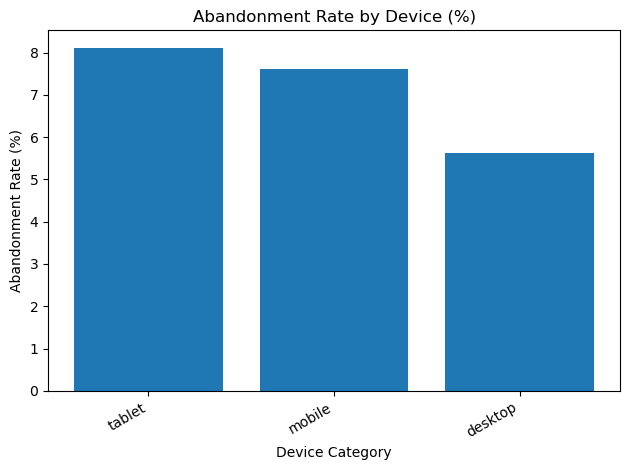

In [572]:

ga_device_df = (
    ga2[['customer_id','next_order_date_utc','device_category']].drop_duplicates()
       .merge(
           windows[['customer_id','next_order_date_utc','is_abandoned']],
           on=['customer_id','next_order_date_utc'],
           how='inner'
       )
       .groupby('device_category', observed=False)['is_abandoned']
       .mean()
       .mul(100)
       .reset_index(name='abandon_rate_%')
       .sort_values('abandon_rate_%', ascending=False)
)
display(ga_device_df.head(20))

# Chart
plt.figure()
plt.bar(ga_device_df['device_category'].astype(str), ga_device_df['abandon_rate_%'])
plt.title("Abandonment Rate by Device (%)")
plt.xlabel("Device Category")
plt.ylabel("Abandonment Rate (%)")
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

,cold_drink_channel_description,abandon_rate_%
7,Store,7.626929
5,Institution,7.487401
8,Workplace,7.368859
4,Hotel,6.647624
0,Attraction,6.597434
6,Restaurant,6.196887
2,Distributor,4.059041
1,Clinic,3.737605
3,Hot Beverage,1.892066


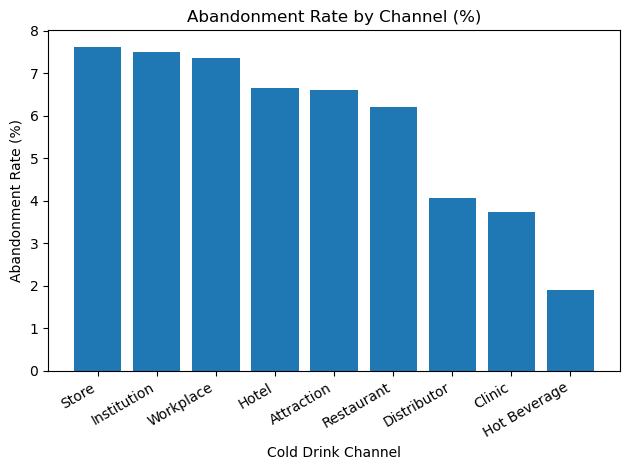

In [573]:
# Channel abandonment (%)
if 'cold_drink_channel_description' in customer.columns:
    channel_df = (
        windows[['customer_id','is_abandoned']]
            .merge(
                customer[['customer_id','cold_drink_channel_description']].drop_duplicates(),
                on='customer_id', how='left'
            )
            .groupby('cold_drink_channel_description', observed=False)['is_abandoned']
            .mean()
            .mul(100)
            .reset_index(name='abandon_rate_%')
            .sort_values('abandon_rate_%', ascending=False)
    )
else:
    channel_df = pd.DataFrame(columns=['cold_drink_channel_description','abandon_rate_%'])

display(channel_df.head(20))

# Chart
if not channel_df.empty:
    plt.figure()
    plt.bar(channel_df['cold_drink_channel_description'].astype(str), channel_df['abandon_rate_%'])
    plt.title("Abandonment Rate by Channel (%)")
    plt.xlabel("Cold Drink Channel")
    plt.ylabel("Abandonment Rate (%)")
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.show()

<a id="20"></a>
### b. Behavioral Patterns

,abandoned_flag(1=yes),total_events,adds,removes,purchases
0,0,56.23,3.73,0.74,0.65
1,1,68.53,4.55,1.77,0.00


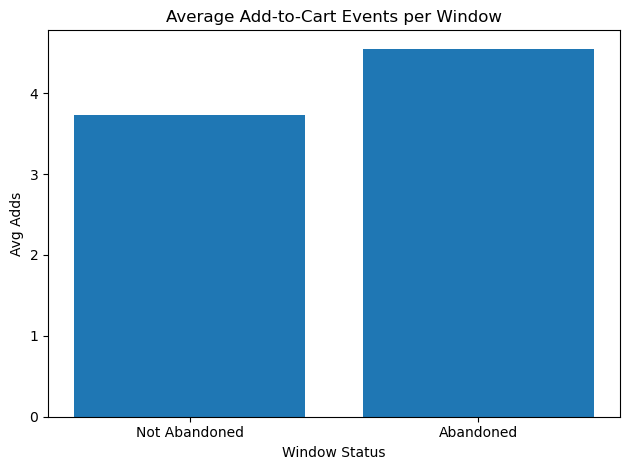

In [575]:
# Count events per window
events_per_window = (
    ga2.groupby(['customer_id','next_order_date_utc'], observed=False)
       .agg(total_events=('event_name','size'),
            adds=('event_name', lambda s: (s.astype(str).str.lower()=='add_to_cart').sum()),
            removes=('event_name', lambda s: (s.astype(str).str.lower()=='remove_from_cart').sum()),
            purchases=('event_name', lambda s: (s.astype(str).str.lower()=='purchase').sum()))
       .reset_index()
)

behav = (
    windows[['customer_id','next_order_date_utc','is_abandoned']]
      .merge(events_per_window, on=['customer_id','next_order_date_utc'], how='left')
      .fillna({'total_events':0,'adds':0,'removes':0,'purchases':0})
)

behav_summary = (
    behav.groupby('is_abandoned', observed=False)[['total_events','adds','removes','purchases']]
         .mean()
         .round(2)
         .reset_index()
         .rename(columns={'is_abandoned':'abandoned_flag(1=yes)'})
)
display(behav_summary)

# average adds by abandon flag
plt.figure()
x = ['Not Abandoned','Abandoned']
vals = [
    behav_summary.loc[behav_summary['abandoned_flag(1=yes)']==0, 'adds'].values[0] if (behav_summary['abandoned_flag(1=yes)']==0).any() else 0,
    behav_summary.loc[behav_summary['abandoned_flag(1=yes)']==1, 'adds'].values[0] if (behav_summary['abandoned_flag(1=yes)']==1).any() else 0
]
plt.bar(x, vals)
plt.title("Average Add-to-Cart Events per Window")
plt.xlabel("Window Status")
plt.ylabel("Avg Adds")
plt.tight_layout()
plt.show()


<a id="21"></a>
### d. Customer & Frequency

<a id="22"></a>
### e.Temporal Patterns

,month,abandon_rate_%
0,2024-06,1.139896
1,2024-07,2.834800
2,2024-08,4.348888
3,2024-09,4.885563
4,2024-10,7.418273
5,2024-11,6.476147
6,2024-12,5.981445
7,2025-01,6.288770
8,2025-02,6.208015
9,2025-03,6.619938


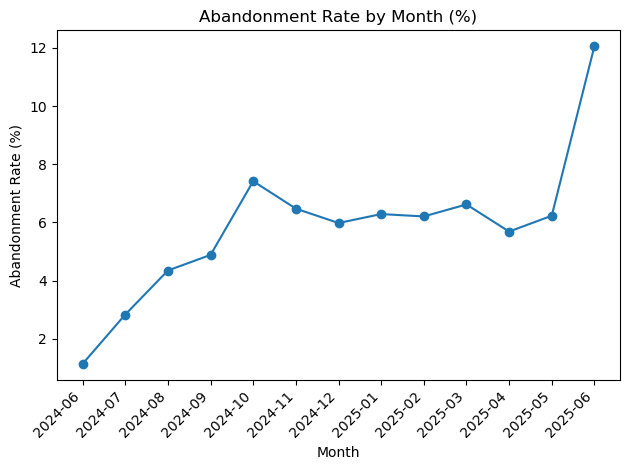

In [578]:
# Ensure tz-aware → month string "YYYY-MM"
tmp = windows[['next_order_date_utc','is_abandoned']].copy()
tmp['next_order_date_utc'] = tmp['next_order_date_utc'].dt.tz_convert('UTC')

# Month label and proper sortable month key
tmp['month'] = tmp['next_order_date_utc'].dt.strftime('%Y-%m')
tmp['month_key'] = pd.to_datetime(tmp['month'], format='%Y-%m', errors='coerce')

abandon_by_month = (
    tmp.dropna(subset=['month_key'])
       .groupby('month', observed=False)['is_abandoned']
       .mean()
       .mul(100)
       .reset_index(name='abandon_rate_%')
       .assign(month_key=lambda d: pd.to_datetime(d['month'], format='%Y-%m'))
       .sort_values('month_key', kind='mergesort')  # stable sort
       .drop(columns=['month_key'])
)

display(abandon_by_month)

# Plot
plt.figure()
if not abandon_by_month.empty:
    plt.plot(abandon_by_month['month'], abandon_by_month['abandon_rate_%'], marker='o')
    plt.title("Abandonment Rate by Month (%)")
    plt.xlabel("Month")
    plt.ylabel("Abandonment Rate (%)")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
else:
    plt.title("Abandonment Rate by Month (%)\n(no data)")
    plt.axis('off')
plt.show()

# Predictive Machine Learning Model

**Question 1:** What (sequence of) behaviors are the strongest predictors of cart abandonment?  
**KPI:** Frequency and type of events before abandonment across sessions.  

**Question 2:** What behaviors lead to a customer returning to the cart after abandonment?  
**Recovery:** Completed checkout after initial cart abandonment within X days.  
**KPI:** Recovery rate by user behavior / device.  

**Question 3:** What does the customer do after cart abandonment? Either go to another platform or churn?  
**KPI:** Abandonment-to-alternative-method conversion rate.  


This machine learning practice is supervised
- Logistic Regression Estimate
      - Regresson Basic
      - Boosted Regression
      - Regression with Regularlization
- Causal Inference Model
- Classification model (binary: abandoned vs. purchased)
  - Random Forest
  - XGBoost
  - Logistic Regression

Vistulization
- Heatmap
- chart to correlation


In [580]:
abandonment_rate_pct = customer_windowed['is_abandoned_count'].mean() * 100
print(f"Cart Abandonment Rate: {abandonment_rate_pct:.2f}%")


Cart Abandonment Rate: 48.82%


In [581]:
# Count of abandoned and total carts
abandoned_count = (customer_windowed['is_abandoned_count'] >= 1).sum()
total_count = customer_windowed['is_abandoned_count'].count()

# Abandonment rate
abandonment_rate = abandoned_count / total_count

print(f"Abandoned carts: {abandoned_count}")
print(f"Total carts: {total_count}")
print(f"Abandonment rate: {abandonment_rate:.2%}")


Abandoned carts: 1875
Total carts: 6334
Abandonment rate: 29.60%


In [582]:
customer_windowed['is_abandoned_count'].value_counts()

is_abandoned_count
0.0     4459
1.0     1174
2.0      414
3.0      167
4.0       61
5.0       35
6.0       12
7.0        5
9.0        3
8.0        3
12.0       1
Name: count, dtype: int64

## 3. Modelling (Linh Do) 

Step 1: Preprocessing
- Remove the windows where customer never adds an item to cart
- Filling in missing values
- Remove date time columns since machine learning model can't handle
- Remove 'customer_id', 'added_in_window', 'purchased_in_window' column

Step 2: Feature Engineering

Step 3: Downsample the windows dataset and encode categorical variables and standardize data

Step 4: Modelling

- Boosted Logistic Regression
- Regression with regularization
- Decision tree
- Gradient boosting with regularization

In [584]:
windows.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52481 entries, 0 to 52480
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype              
---  ------                           --------------  -----              
 0   customer_id                      52481 non-null  int64              
 1   next_order_date_utc              52481 non-null  datetime64[ns, UTC]
 2   added_in_window                  52481 non-null  bool               
 3   purchased_in_window              52481 non-null  bool               
 4   is_abandoned                     52481 non-null  int64              
 5   missed_reorder                   52481 non-null  int64              
 6   view_item_list                   38343 non-null  float64            
 7   add_to_cart                      38343 non-null  float64            
 8   update_cart                      38343 non-null  float64            
 9   view_site_search                 38343 non-null  float64            
 10

In [585]:
windows_modelling.info()

<class 'pandas.core.frame.DataFrame'>
Index: 30500 entries, 9 to 52472
Columns: 162 entries, is_abandoned to avg_units_per_order
dtypes: category(3), float64(154), int64(5)
memory usage: 37.3 MB


In [591]:
## Step 1: Preprocessing
# Remove the windows where customers never add an item to cart
windows_modelling = windows[windows['added_in_window'] == True]

# fill na values with 0
windows_modelling[['total_orders', 'last_order_time', 'total_units_ordered', 'avg_units_per_order', 'view_item_list', 'add_to_cart', 'update_cart', 'view_site_search', 'proceed_to_checkout', 'user_engagement']] = windows_modelling[['total_orders', 'last_order_time', 'total_units_ordered', 'avg_units_per_order', 'view_item_list', 'add_to_cart', 'update_cart', 'view_site_search', 'proceed_to_checkout', 'user_engagement']].fillna(0)

# check if there is any na values after filling
print(windows_modelling.isna().sum())

# Remove date time columns 'next_order_date_utc', 'last_order_time', and 'customer_id', 'added_in_window', 'purchased_in_window'
windows_modelling = windows_modelling.drop(['next_order_date_utc', 'last_order_time', 'customer_id', 'added_in_window', 'purchased_in_window'], axis = 1)

windows_modelling.head()

customer_id                        0
next_order_date_utc                0
added_in_window                    0
purchased_in_window                0
is_abandoned                       0
missed_reorder                     0
view_item_list                     0
add_to_cart                        0
update_cart                        0
view_site_search                   0
proceed_to_checkout                0
user_engagement                    0
access_desktop                     0
access_mobile                      0
access_tablet                      0
sales_office_description           0
shipping_conditions_description    0
cold_drink_channel_description     0
total_orders                       0
last_order_time                    0
total_units_ordered                0
avg_units_per_order                0
dtype: int64


/var/folders/p2/nf9m5p050ln86bxjb9cb4l6c0000gn/T/ipykernel_3134/3472321262.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  windows_modelling[['total_orders', 'last_order_time', 'total_units_ordered', 'avg_units_per_order', 'view_item_list', 'add_to_cart', 'update_cart', 'view_site_search', 'proceed_to_checkout', 'user_engagement']] = windows_modelling[['total_orders', 'last_order_time', 'total_units_ordered', 'avg_units_per_order', 'view_item_list', 'add_to_cart', 'update_cart', 'view_site_search', 'proceed_to_checkout', 'user_engagement']].fillna(0)


,is_abandoned,missed_reorder,view_item_list,add_to_cart,update_cart,view_site_search,proceed_to_checkout,user_engagement,access_desktop,access_mobile,access_tablet,sales_office_description,shipping_conditions_description,cold_drink_channel_description,total_orders,total_units_ordered,avg_units_per_order
9,0,0,13.0,1.0,15.0,2.0,8.0,0.0,1,0,0,"Draper, UT",48 Hours,Restaurant,37.0,73.0,1.972973
12,0,0,4.0,1.0,5.0,0.0,1.0,0.0,1,0,0,"Draper, UT",48 Hours,Restaurant,37.0,73.0,1.972973
13,0,0,2.0,1.0,10.0,0.0,6.0,0.0,1,0,0,"Draper, UT",48 Hours,Restaurant,37.0,73.0,1.972973
15,0,0,2.0,1.0,5.0,0.0,3.0,0.0,1,0,0,"Draper, UT",48 Hours,Restaurant,37.0,73.0,1.972973
31,0,0,5.0,1.0,3.0,0.0,1.0,0.0,1,0,0,"Draper, UT",48 Hours,Distributor,1314.0,2098.0,1.596651


In [643]:
# convert binary variables to categorical data type
categorical_cols = ['is_abandoned', 'missed_reorder', 'access_desktop', 'access_mobile', 'access_tablet']
windows_modelling[categorical_cols] = windows_modelling[categorical_cols].astype('category')

windows_modelling.info()

# drop sales_office_description
windows_modelling = windows_modelling.drop(columns=['sales_office_description'], errors='ignore')


<class 'pandas.core.frame.DataFrame'>
Index: 30500 entries, 9 to 52472
Data columns (total 17 columns):
 #   Column                           Non-Null Count  Dtype   
---  ------                           --------------  -----   
 0   is_abandoned                     30500 non-null  category
 1   missed_reorder                   30500 non-null  category
 2   view_item_list                   30500 non-null  float64 
 3   add_to_cart                      30500 non-null  float64 
 4   update_cart                      30500 non-null  float64 
 5   view_site_search                 30500 non-null  float64 
 6   proceed_to_checkout              30500 non-null  float64 
 7   user_engagement                  30500 non-null  float64 
 8   access_desktop                   30500 non-null  category
 9   access_mobile                    30500 non-null  category
 10  access_tablet                    30500 non-null  category
 11  sales_office_description         30500 non-null  category
 12  shipping_

/opt/anaconda3/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:868: FutureWarning: `sparse` was renamed to `sparse_output` in version 1.2 and will be removed in 1.4. `sparse_output` is ignored unless you leave `sparse` to its default value.
  warnings.warn(


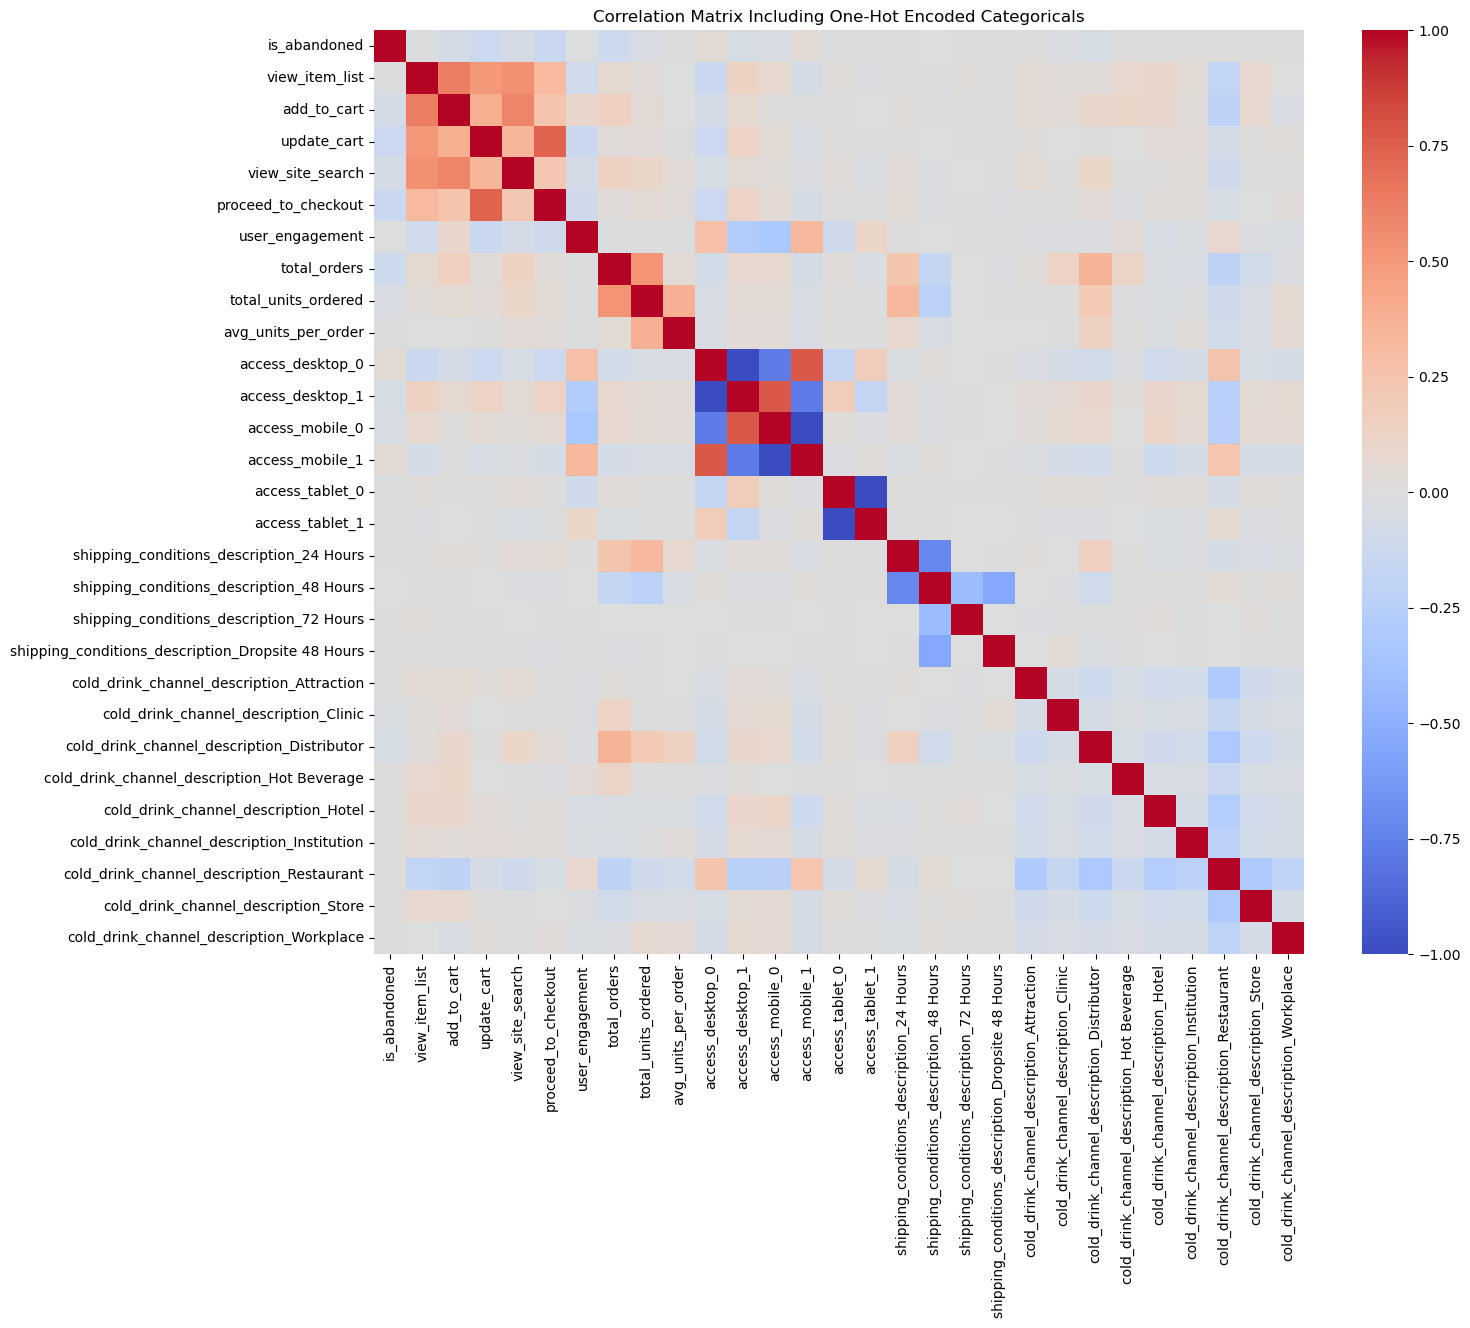

Correlation with is_abandoned:
 is_abandoned                                         1.000000
access_desktop_0                                     0.048291
access_mobile_1                                      0.043426
shipping_conditions_description_72 Hours             0.015277
cold_drink_channel_description_Hot Beverage          0.014622
cold_drink_channel_description_Workplace             0.013909
cold_drink_channel_description_Store                 0.012633
cold_drink_channel_description_Restaurant            0.011999
access_tablet_1                                      0.011653
cold_drink_channel_description_Attraction            0.011545
cold_drink_channel_description_Institution           0.009405
shipping_conditions_description_Dropsite 48 Hours    0.007338
avg_units_per_order                                  0.005858
cold_drink_channel_description_Hotel                 0.002229
shipping_conditions_description_48 Hours            -0.002790
user_engagement                       

In [657]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder

# Select categorical columns (exclude target)
categorical_cols = [
    'access_desktop', 'access_mobile', 'access_tablet',
    'shipping_conditions_description',
    'cold_drink_channel_description'
]

# One-hot encode categorical features
ohe = OneHotEncoder(sparse=False, drop=None)
X_cat = ohe.fit_transform(windows_modelling[categorical_cols])
X_cat_df = pd.DataFrame(X_cat, columns=ohe.get_feature_names_out(categorical_cols), index=windows_modelling.index)

# Select numeric columns (exclude target 'is_abandoned')
numeric_cols = windows_modelling.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Combine one-hot encoded categorical features and numeric features
# Keep 'is_abandoned' as numeric (0/1) for correlation
data_for_corr = pd.concat(
    [windows_modelling['is_abandoned'].astype(int), windows_modelling[numeric_cols], X_cat_df], axis=1
)

# Compute correlation
corr_matrix = data_for_corr.corr()

# Display correlation matrix heatmap
plt.figure(figsize=(15,12))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', center=0)
plt.title("Correlation Matrix Including One-Hot Encoded Categoricals")
plt.show()

# Correlation with target only
target_corr = corr_matrix['is_abandoned'].sort_values(ascending=False)
print("Correlation with is_abandoned:\n", target_corr)


In [645]:
## Step 3: Downsample the windows dataset and encode categorical variables
# import libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils import resample
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler


# Features & target
y = windows_modelling['is_abandoned']
X = windows_modelling.drop(columns=['is_abandoned', 'missed_reorder'])

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Downsample majority class
train_data = pd.concat([X_train, y_train], axis=1)
majority = train_data[train_data['is_abandoned'] == 0]
minority = train_data[train_data['is_abandoned'] == 1]

majority_downsampled = resample(
    majority,
    replace=False,
    n_samples=len(minority),
    random_state=42
)

train_downsampled = pd.concat([minority, majority_downsampled]).sample(frac=1, random_state=42)

X_train_down = train_downsampled.drop(columns=['is_abandoned'], errors='ignore')
y_train_down = train_downsampled['is_abandoned']

# Select categorical columns (exclude target and already dropped columns)
categorical_cols = [
    'access_desktop', 'access_mobile', 'access_tablet',
    'shipping_conditions_description', 
    'cold_drink_channel_description'
]

# Initialize OneHotEncoder
ohe = OneHotEncoder(handle_unknown='ignore', sparse=False)

# Fit on training data and transform
X_train_cat = ohe.fit_transform(X_train_down[categorical_cols])
X_test_cat = ohe.transform(X_test[categorical_cols])

# Convert to DataFrame with proper column names
X_train_cat = pd.DataFrame(X_train_cat, columns=ohe.get_feature_names_out(categorical_cols), index=X_train_down.index)
X_test_cat = pd.DataFrame(X_test_cat, columns=ohe.get_feature_names_out(categorical_cols), index=X_test.index)

# Drop original categorical columns and concatenate encoded ones
X_train_down = pd.concat([X_train_down.drop(columns=categorical_cols), X_train_cat], axis=1)
X_test = pd.concat([X_test.drop(columns=categorical_cols), X_test_cat], axis=1)


# Identify numeric columns (exclude already one-hot encoded categorical columns)
numeric_cols = X_train_down.select_dtypes(include=['int64', 'float64']).columns

scaler = StandardScaler()
X_train_down[numeric_cols] = scaler.fit_transform(X_train_down[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])


/opt/anaconda3/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:868: FutureWarning: `sparse` was renamed to `sparse_output` in version 1.2 and will be removed in 1.4. `sparse_output` is ignored unless you leave `sparse` to its default value.
  warnings.warn(


In [647]:
X_train_down.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4948 entries, 1130 to 33957
Data columns (total 28 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   view_item_list                                     4948 non-null   float64
 1   add_to_cart                                        4948 non-null   float64
 2   update_cart                                        4948 non-null   float64
 3   view_site_search                                   4948 non-null   float64
 4   proceed_to_checkout                                4948 non-null   float64
 5   user_engagement                                    4948 non-null   float64
 6   total_orders                                       4948 non-null   float64
 7   total_units_ordered                                4948 non-null   float64
 8   avg_units_per_order                                4948 non-null   float64
 9   access_de

In [651]:
## Step 4: Modelling
# Logistic Regression
logistic_regression = LogisticRegression(class_weight='balanced', max_iter=1000)
logistic_regression.fit(X_train_down, y_train_down)
y_pred_lr = logistic_regression.predict(X_test)
print("=== Logistic Regression ===")
print(classification_report(y_test, y_pred_lr))

=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.96      0.62      0.76      5482
           1       0.19      0.78      0.30       618

    accuracy                           0.64      6100
   macro avg       0.58      0.70      0.53      6100
weighted avg       0.88      0.64      0.71      6100



In [665]:
# If using one-hot encoded X_train_down
feature_names = X_train_down.columns
coefficients = logistic_regression.coef_[0]

# Create a DataFrame
coef_df = pd.DataFrame({'feature': feature_names, 'coefficient': coefficients})

# Absolute value shows impact magnitude
coef_df['abs_coeff'] = coef_df['coefficient'].abs()

# Sort by absolute impact
coef_df_sorted = coef_df.sort_values(by='abs_coeff', ascending=False)
print(coef_df_sorted)


                                              feature  coefficient  abs_coeff
6                                        total_orders    -1.483191   1.483191
4                                 proceed_to_checkout    -0.438294   0.438294
0                                      view_item_list     0.393681   0.393681
2                                         update_cart    -0.393440   0.393440
1                                         add_to_cart    -0.185920   0.185920
22        cold_drink_channel_description_Hot Beverage     0.146642   0.146642
3                                    view_site_search    -0.136940   0.136940
5                                     user_engagement    -0.114685   0.114685
25          cold_drink_channel_description_Restaurant    -0.082908   0.082908
15           shipping_conditions_description_24 Hours     0.067235   0.067235
11                                    access_mobile_0    -0.062258   0.062258
12                                    access_mobile_1     0.0622

In [659]:
# Boosted Logistic Regression (Gradient Boosting with logistic loss)
blr = GradientBoostingClassifier(
    loss='deviance', n_estimators=200, learning_rate=0.1, max_depth=3, random_state=42
)
blr.fit(X_train_down, y_train_down)
y_pred_blr = blr.predict(X_test)
print("=== Boosted Logistic Regression ===")
print(classification_report(y_test, y_pred_blr))


/opt/anaconda3/lib/python3.11/site-packages/sklearn/ensemble/_gb.py:280: FutureWarning: The loss parameter name 'deviance' was deprecated in v1.1 and will be removed in version 1.3. Use the new parameter name 'log_loss' which is equivalent.
  warnings.warn(


=== Boosted Logistic Regression ===
              precision    recall  f1-score   support

           0       0.97      0.88      0.92      5482
           1       0.42      0.75      0.54       618

    accuracy                           0.87      6100
   macro avg       0.70      0.82      0.73      6100
weighted avg       0.91      0.87      0.89      6100



In [661]:
# Decision Tree
dt = DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, random_state=42)
dt.fit(X_train_down, y_train_down)
y_pred_dt = dt.predict(X_test)
print("=== Decision Tree ===")
print(classification_report(y_test, y_pred_dt))


=== Decision Tree ===
              precision    recall  f1-score   support

           0       0.97      0.88      0.92      5482
           1       0.41      0.73      0.53       618

    accuracy                           0.87      6100
   macro avg       0.69      0.81      0.72      6100
weighted avg       0.91      0.87      0.88      6100



In [663]:
# Gradient Boosting with regularization
gb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_depth=5, random_state=42)
gb.fit(X_train_down, y_train_down)
y_pred_gb = gb.predict(X_test)
print("=== Gradient Boosting ===")
print(classification_report(y_test, y_pred_gb))

=== Gradient Boosting ===
              precision    recall  f1-score   support

           0       0.97      0.88      0.92      5482
           1       0.41      0.75      0.53       618

    accuracy                           0.86      6100
   macro avg       0.69      0.81      0.72      6100
weighted avg       0.91      0.86      0.88      6100



/opt/anaconda3/lib/python3.11/site-packages/xgboost/training.py:183: UserWarning: [18:06:18] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


=== XGBoost Classification Report ===
              precision    recall  f1-score   support

           0       0.97      0.88      0.92      5482
           1       0.41      0.75      0.53       618

    accuracy                           0.87      6100
   macro avg       0.69      0.81      0.73      6100
weighted avg       0.91      0.87      0.88      6100



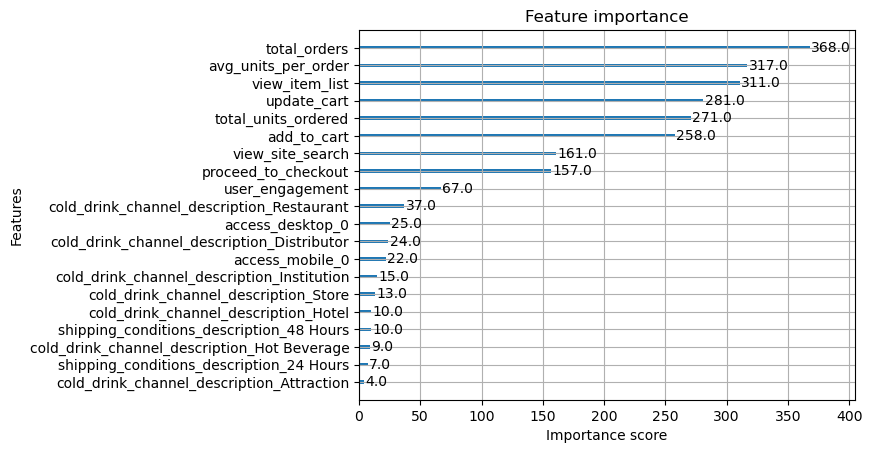

In [671]:
import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix

# Optional: compute scale_pos_weight for imbalance
scale_pos_weight = y_train_down.value_counts()[0] / y_train_down.value_counts()[1]

# Train XGBoost classifier
xgb_model = xgb.XGBClassifier(
    objective='binary:logistic',
    scale_pos_weight=scale_pos_weight,
    eval_metric='logloss',
    use_label_encoder=False,
    random_state=42,
    n_estimators=200,
    max_depth=4,
    learning_rate=0.1
)

xgb_model.fit(X_train_down, y_train_down)

# Predict
y_pred = xgb_model.predict(X_test)

# Evaluate
print("=== XGBoost Classification Report ===")
print(classification_report(y_test, y_pred))

# Feature importance
import matplotlib.pyplot as plt
xgb.plot_importance(xgb_model, max_num_features=20, importance_type='weight')
plt.show()


=== LightGBM Classification Report ===
              precision    recall  f1-score   support

           0       0.97      0.88      0.92      5482
           1       0.41      0.75      0.53       618

    accuracy                           0.86      6100
   macro avg       0.69      0.81      0.72      6100
weighted avg       0.91      0.86      0.88      6100



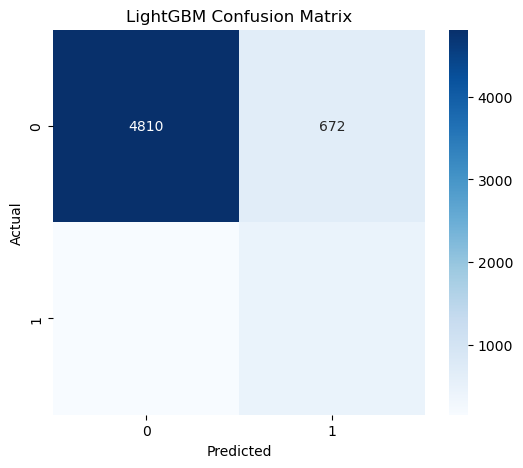

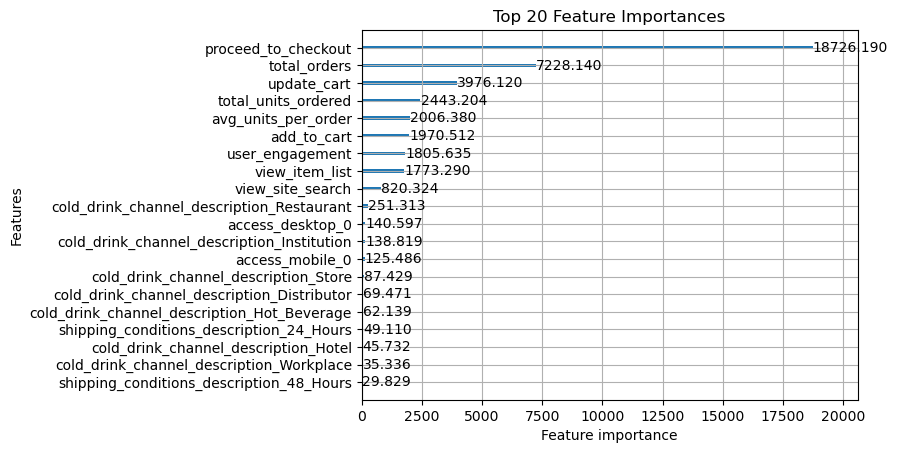

In [687]:

import lightgbm as lgb
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

# Optional: compute class weight to handle imbalance
scale_pos_weight = y_train_down.value_counts()[0] / y_train_down.value_counts()[1]

lgb_model = lgb.LGBMClassifier(
    objective='binary',
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    verbose=-1  # suppress messages
)

lgb_model.fit(X_train_down, y_train_down)

y_pred = lgb_model.predict(X_test)

print("=== LightGBM Classification Report ===")
print(classification_report(y_test, y_pred))

# Optional: confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('LightGBM Confusion Matrix')
plt.show()

lgb.plot_importance(lgb_model, max_num_features=20, importance_type='gain')
plt.title('Top 20 Feature Importances')
plt.show()


In [693]:
from lightgbm import LGBMClassifier


# Train LightGBM Classifier
# ===============================
# Handle imbalance with scale_pos_weight
scale_pos_weight = y_train_down.value_counts()[0] / y_train_down.value_counts()[1]

lgb_model = LGBMClassifier(
    objective='binary',
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    verbose=-1
)

lgb_model.fit(X_train_down, y_train_down)

# ===============================
# Step 7: Evaluate
# ===============================
y_pred = lgb_model.predict(X_test)
y_pred_prob = lgb_model.predict_proba(X_test)[:, 1]

print("=== LightGBM Classifier ===")
print(classification_report(y_test, y_pred))

# Optional: Feature Importances
importances = pd.Series(lgb_model.feature_importances_, index=X_train_down.columns).sort_values(ascending=False)
print("Top 10 feature importances:\n", importances.head(10))


=== LightGBM Classifier ===
              precision    recall  f1-score   support

           0       0.97      0.88      0.92      5482
           1       0.41      0.75      0.53       618

    accuracy                           0.86      6100
   macro avg       0.69      0.81      0.72      6100
weighted avg       0.91      0.86      0.88      6100

Top 10 feature importances:
 total_orders                                 964
avg_units_per_order                          828
update_cart                                  647
view_item_list                               641
add_to_cart                                  604
total_units_ordered                          599
proceed_to_checkout                          359
view_site_search                             356
user_engagement                              160
cold_drink_channel_description_Restaurant     93
dtype: int32


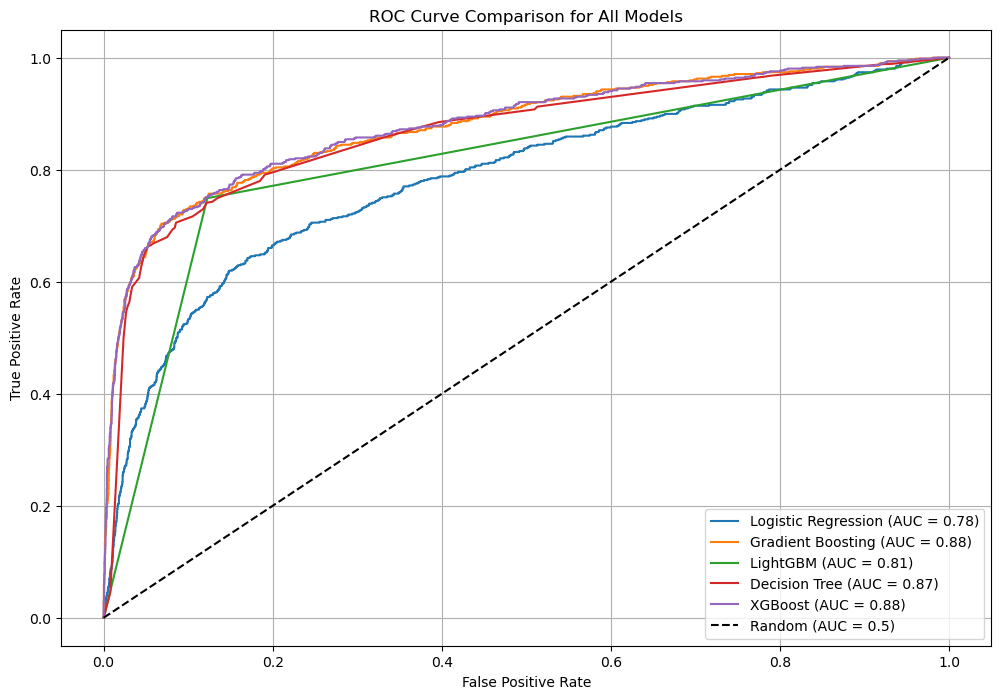

In [701]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Make sure all models have predicted probabilities
# For DecisionTreeClassifier, use predict_proba
# For XGBoost, use predict_proba with output_margin=False

models = {
    'Logistic Regression': logistic_regression,
    'Gradient Boosting': gb,
    'LightGBM': lgb_model,   # replace with your LGBM model variable
    'Decision Tree': dt,  # replace with your DecisionTreeClassifier variable
    'XGBoost': xgb_model    # replace with your XGBClassifier variable
}

# Compute predicted probabilities for the positive class
y_pred_probs = {
    'Logistic Regression': logistic_regression.predict_proba(X_test)[:, 1],
    'Gradient Boosting': gb.predict_proba(X_test)[:, 1],
    'LightGBM': lgb_model.predict(X_test),
    'Decision Tree': dt.predict_proba(X_test)[:, 1],
    'XGBoost': xgb_model.predict_proba(X_test)[:, 1]
}

# Plot ROC curves
plt.figure(figsize=(12, 8))

for name, y_prob in y_pred_probs.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc_score:.2f})')

# Random baseline
plt.plot([0, 1], [0, 1], 'k--', label='Random (AUC = 0.5)')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison for All Models')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()
